In [1]:
%pip install geopandas -q


StatementMeta(, d0431502-05a0-45ba-863b-1a108e2ccf27, 7, Finished, Available, Finished, True)


Note: you may need to restart the kernel to use updated packages.



StatementMeta(, d0431502-05a0-45ba-863b-1a108e2ccf27, 9, Finished, Available, Finished, False)

Archive : 252 MB
Fichier utilisé : /tmp/filosofi/france_metro/carreaux_200m_met.shp
toulon : 4611 carreaux | population : 417066
marseille : 3148 carreaux | population : 772114
Sauvegardé


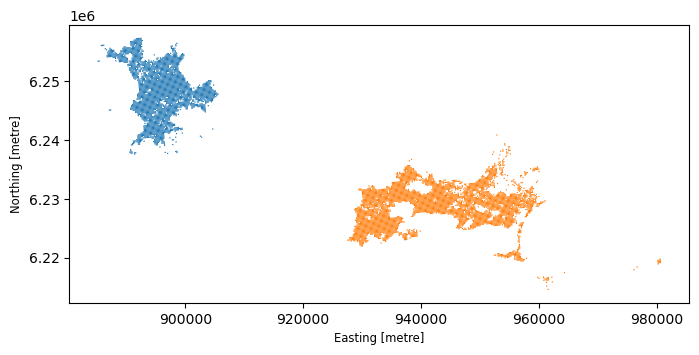

In [2]:
import geopandas as gpd, pandas as pd, requests, zipfile, glob, os

# ---------- Paramètres ----------
URL_POP = "https://www.insee.fr/fr/statistiques/fichier/8735162/Filosofi2021_carreaux_200m_shp.zip"
BASE = "/lakehouse/default/Files/population"
BRUT = f"{BASE}/brut"
os.makedirs(BRUT, exist_ok=True)

# ---------- 1. Télécharger le fichier INSEE (même zip que sur le PC, 240 Mo) ----------
archive = f"{BRUT}/Filosofi2021_carreaux_200m_shp.zip"
if not os.path.exists(archive):
    with requests.get(URL_POP, stream=True, timeout=900) as r:
        r.raise_for_status()
        with open(archive, "wb") as f:
            for morceau in r.iter_content(1024 * 1024):
                f.write(morceau)
print("Archive :", round(os.path.getsize(archive) / 1e6), "MB")

# ---------- 2. Décompresser seulement la France métropolitaine (carreaux_200m_met) ----------
with zipfile.ZipFile(archive) as z:
    met = [n for n in z.namelist() if "_met." in n.lower()]
    z.extractall("/tmp/filosofi", members=met)
shp = glob.glob("/tmp/filosofi/**/carreaux_200m_met.shp", recursive=True)[0]
print("Fichier utilisé :", shp)

# ---------- 3. Contours des 2 villes ----------
tpm = gpd.read_file("https://geo.api.gouv.fr/epcis/248300543/communes?fields=nom,code,contour&format=geojson&geometry=contour")
mrs = gpd.read_file("https://geo.api.gouv.fr/communes?code=13055&fields=nom,code,contour&format=geojson&geometry=contour")
zones = {"toulon": tpm.to_crs(2154).union_all(), "marseille": mrs.to_crs(2154).union_all()}

# ---------- 4. Garder les carreaux de chaque ville ----------
crs = gpd.read_file(shp, rows=1).crs
morceaux = []
for ville, zone in zones.items():
    bbox = tuple(gpd.GeoSeries([zone], crs=2154).to_crs(crs).total_bounds)
    g = gpd.read_file(shp, bbox=bbox).to_crs(2154)
    g = g[g.centroid.within(zone)].copy()
    g["ville"] = ville
    morceaux.append(g)
    print(ville, ":", len(g), "carreaux | population :", round(g["ind"].sum()))
pop = gpd.GeoDataFrame(pd.concat(morceaux), crs=2154)

# ---------- 5. Sauvegarder ----------
pop.to_parquet(f"{BASE}/population_toulon_marseille.parquet")
pop.plot(column="ville", figsize=(8, 8))
print("Sauvegardé")